# 11 — Equity pricing-error intercepts and joint zero-alpha tests

Add constant pricing-error intercepts for **World, US and Hungarian equities**, for both USD and EUR
investors. Use the retained `scalar11` and `grouped21` covariance models on the same frozen
**321 months, 2000-01 through 2026-09**. Constant Hungarian local pricing is the main comparison,
following notebook 10; its audited time-varying local design is a sensitivity.

Run notebook 10 first, then **Run All** in the existing Miniconda **base** kernel. Inputs are read
locally without downloads or API keys. All risk prices and covariance parameters are jointly
re-estimated when alphas are freed. The extension is in [pricing_error_tests.py](pricing_error_tests.py).
Earlier engines, notebooks and outputs remain unchanged.

In [1]:
SNAPSHOT="data/fixed_2026-11-13/from_2000-01"
UPSTREAM="output/10_time_varying_local/fixed_2026-11-13/2000-01_2026-09/local_change"
COVARIANCE_MODELS=["scalar11","grouped21"]
RUN_TV_LOCAL_SENSITIVITY=True
HAC_LAGS=[0,3,6,12]
TEST_LAGS=12
MAX_ITER=2600
SE_STEP_TOL=.01
REUSE_FITS=True
MODEL_VERSION="joint_equity_alphas_v1"

from pathlib import Path
from io import BytesIO
import hashlib,importlib,importlib.metadata,json,os,platform,sys
ROOT=Path.cwd()
os.environ.setdefault("MPLCONFIGDIR",str(ROOT/".cache"/"matplotlib"))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from packaging.version import Version
if Version(importlib.metadata.version("statsmodels"))<Version("0.15.0"):raise RuntimeError("Update statsmodels to 0.15.0 and restart the same base kernel.")
if "statsmodels" in sys.modules and sys.modules["statsmodels"].__version__!=importlib.metadata.version("statsmodels"):
    raise RuntimeError("Restart the same kernel to discard old statsmodels imports.")
from statsmodels.stats.multitest import multipletests
from IPython.display import display,Markdown
if str(ROOT) not in sys.path:sys.path.insert(0,str(ROOT))
import pricing_robustness as base
import covariance_robustness as covariance
import local_risk_pricing as local
import pricing_error_tests as model
importlib.reload(base);importlib.reload(covariance);importlib.reload(local);importlib.reload(model)
versions={p:importlib.metadata.version(p) for p in ["numpy","pandas","scipy","statsmodels","matplotlib"]}
engine_hashes={p:hashlib.sha256((ROOT/p).read_bytes()).hexdigest() for p in ["pricing_robustness.py","covariance_robustness.py","local_risk_pricing.py","pricing_error_tests.py"]}
print("Python:",sys.executable);print("Packages:",versions)
if not COVARIANCE_MODELS or len(set(COVARIANCE_MODELS))!=len(COVARIANCE_MODELS) or any(m not in ["scalar11","grouped21"] for m in COVARIANCE_MODELS):raise ValueError("Use the retained covariance models.")
if not HAC_LAGS or 0 not in HAC_LAGS or len(set(HAC_LAGS))!=len(HAC_LAGS) or any(type(h)!=int or h<0 for h in HAC_LAGS):raise ValueError("Include zero and distinct nonnegative integer HAC lags.")
pd.set_option("display.max_columns",18);pd.set_option("display.max_rows",50);pd.options.display.float_format=lambda x:f"{x:.6g}"
plt.rcParams.update({"figure.dpi":120,"font.size":10,"axes.spines.top":False,"axes.spines.right":False,"axes.grid":True,"grid.alpha":.16})
source,upstream=ROOT/SNAPSHOT,ROOT/UPSTREAM
manifest=json.loads((source/"manifest.json").read_text());raw=(source/"dataset.csv").read_bytes()
if not manifest.get("sealed") or hashlib.sha256(raw).hexdigest()!=manifest["exports"]["dataset.csv"]:raise ValueError("Frozen dataset checksum differs.")
data=pd.read_csv(BytesIO(raw),index_col=0,float_precision="round_trip");data.index=pd.PeriodIndex(data.index,freq="M",name="month")
if not data.index.equals(pd.period_range(data.index[0],data.index[-1],freq="M")):raise ValueError("Discontinuous model months.")
if max(HAC_LAGS)>=len(data):raise ValueError("HAC bandwidth exceeds the sample.")
upstream_hashes,conditioning_hashes={},{}
def upstream_bytes(name):
    content=(upstream/name).read_bytes();upstream_hashes[name]=hashlib.sha256(content).hexdigest();return content
prior=json.loads(upstream_bytes("estimation_manifest.json"))
if (prior["source_dataset_sha256"]!=manifest["exports"]["dataset.csv"] or prior["first"]!=str(data.index[0]) or prior["last"]!=str(data.index[-1]) or prior["observations"]!=len(data)):
    raise ValueError("Notebook 10 sample differs.")
for name,digest in prior["engines"].items():
    if engine_hashes[name]!=digest:raise ValueError("An upstream likelihood engine changed.")
conditioning_root=ROOT/prior["conditioning_root"]
def conditioning_bytes(name):
    content=(conditioning_root/name).read_bytes();digest=hashlib.sha256(content).hexdigest()
    if digest!=prior["conditioning_file_sha256"][name]:raise ValueError(f"Conditioning checksum differs: {name}")
    conditioning_hashes[name]=digest;return content
local_specifications=["constant"]+([prior["local_primary"]] if RUN_TV_LOCAL_SENSITIVITY else [])
old_summary=pd.read_csv(BytesIO(upstream_bytes("fit_summary.csv")),index_col=0,float_precision="round_trip")
inflation=pd.read_csv(BytesIO(conditioning_bytes("inflation_reconstruction.csv")),index_col=0,float_precision="round_trip")
inflation.index=pd.PeriodIndex(inflation.index,freq="M")
normalizers=pd.read_csv(BytesIO(upstream_bytes("local_instrument_normalizers.csv")),index_col=0,float_precision="round_trip").set_index(["perspective","transform","instrument"]).sort_index()
samples,designs,design_columns,references={}, {}, {}, {}
for currency,gap in [("USD","US_HU"),("EUR","EA_HU")]:
    designs[currency],design_columns[currency]={},{}
    for label in ["W","H","O"]:
        z=pd.read_csv(BytesIO(conditioning_bytes(f"conditioning_{currency.lower()}_{label}.csv")),index_col=0,float_precision="round_trip")
        if not pd.PeriodIndex(z.index,freq="M").equals(data.index):raise ValueError("Conditioning months differ.")
        designs[currency][label]=z.to_numpy();design_columns[currency][label]=list(z.columns)
    for specification in local_specifications:
        if specification=="constant":z=np.ones((len(data),1));columns=["constant"]
        else:
            frame=pd.DataFrame({f"inflation_gap_{specification}_lag2_pp":inflation[f"{specification}_{gap}_lag2_pp"],"floating_regime_known":data["floating_regime_known"]},index=data.index)
            stats=normalizers.loc[(currency,specification)].reindex(frame.columns)
            np.testing.assert_allclose(stats["mean"],frame.mean(),atol=1e-12,rtol=0)
            np.testing.assert_allclose(stats["sd"],frame.std(ddof=1),atol=1e-12,rtol=0)
            z=np.c_[np.ones(len(data)),((frame-frame.mean())/frame.std(ddof=1)).to_numpy()];columns=["constant"]+list(frame.columns)
        designs[currency][specification]=z;design_columns[currency][specification]=columns
        for name in COVARIANCE_MODELS:
            key=f"{currency}_{name}_{specification}"
            with np.load(BytesIO(upstream_bytes(f"parameters_{key}.npz")),allow_pickle=False) as a:references[key]={k:a[k].copy() for k in a.files}
    equity=data[[f"rx_{a}_{currency.lower()}" for a in ["world","us","hu"]]].to_numpy()*100
    fx=np.c_[data[f"fx_huf_{currency.lower()}"]*100,data["fx_eur_usd"]*100*(1 if currency=="USD" else -1)]
    samples[currency]=np.c_[equity,fx]
OUT=ROOT/"output"/"11_pricing_errors"/source.parent.name/f"{data.index[0]}_{data.index[-1]}"/"equity_alphas"
OUT.mkdir(parents=True,exist_ok=True)
EQUITIES=["World","US","Hungary"]
display(pd.DataFrame({"first":[str(data.index[0])],"last":[str(data.index[-1])],"months":[len(data)],"equity_intercepts":[", ".join(EQUITIES)],"main_local_price":["constant"]}))

Python: /Users/lajosgalambos/miniconda3/bin/python
Packages: {'numpy': '2.4.4', 'pandas': '3.0.2', 'scipy': '1.17.1', 'statsmodels': '0.15.0', 'matplotlib': '3.10.8'}


,first,last,months,equity_intercepts,main_local_price
0,2000-01,2026-09,321,"World, US, Hungary",constant


## 1. Specify the alpha test and verify the nested model

For equity $i\in\{W,US,HU\}$, add a constant pricing-error intercept:

$$\boxed{E_{t-1}[r^e_{i,t}]=\alpha_i+\lambda_{W,t}H_{iW,t}
+\lambda_{H,t}H_{iH,t}+\lambda_{O,t}H_{iO,t}+\lambda_{i,t}H_{ii,t}.}$$

The local term is present for US and Hungary only; World has no additional local term. The two FX
mean equations retain the existing pricing restriction, without additional intercepts. This follows
the supplied draft's asset-specific equity-intercept check (section 4.1); our data, two-FX basis,
instruments and covariance choices remain adaptations. See the
[available draft](https://www.efmaefm.org/0EFMAMEETINGS/EFMA%20ANNUAL%20MEETINGS/2005-Milan/papers/14-antell_paper.pdf).

**Primary null:** $H_0:\alpha_W=\alpha_{US}=\alpha_{HU}=0$ (**3 df**). The intercepts measure
constant conditional-mean discrepancies in monthly log percentage points, not realized trading
profits. They are distinct from both local risk prices and the ARCH weights also often called alpha.
All means, covariance parameters and alphas are estimated together: adding alpha changes innovations,
which change subsequent conditional covariances and priced premia.

Alphas are optimized in units of each equity's fixed sample standard deviation, with no artificial
alpha bounds; exports restore percentage-point units. Adding three coefficients gives **37/44**
parameters (constant local price, scalar/grouped) or **39/46** (time-varying local sensitivity).
Zero alpha nests exactly. Before estimation verify every reference fit, the zero-alpha limit,
analytic gradients with nonzero alphas, and preliminary mean-loading rank. These are identification
screens; the full re-estimated Hessian remains decisive.

In [2]:
def make_case(currency,name,specification,free_alpha):
    pdsg={a:designs[currency][a].copy() for a in ["W","H","O"]};pdsg["L"]=designs[currency][specification].copy()
    columns={a:design_columns[currency][a] for a in ["W","H","O"]};columns["L"]=design_columns[currency][specification]
    parent=f"{currency}_{name}_{specification}";y=samples[currency]
    if any(not np.isfinite(z).all() or np.linalg.matrix_rank(z)!=z.shape[1] for z in pdsg.values()):raise ValueError("Invalid inherited price design.")
    return {"id":parent+("_free" if free_alpha else "_zero"),"parent":parent,"currency":currency,"name":name,"specification":specification,
            "free_alpha":free_alpha,"y":y,"pdesign":pdsg,"columns":columns,"scales":y.std(axis=0,ddof=1)}
def args(case):return (case["y"],case["pdesign"],case["scales"],case["name"],case["free_alpha"])
checks,loading_rows=[],[]
for currency in ["USD","EUR"]:
    for name in COVARIANCE_MODELS:
        for specification in local_specifications:
            case=make_case(currency,name,specification,False);saved=references[case["parent"]]
            f=model.filter_model(saved["theta"],*args(case))
            for new,old in [("H","H"),("mu","mu"),("errors","residuals"),("scores","scores")]:np.testing.assert_allclose(f[new],saved[old],atol=1e-8,rtol=1e-9)
            np.testing.assert_allclose(-f["losses"].sum(),old_summary.loc[case["parent"],"loglik"],atol=1e-8,rtol=0)
            free=make_case(currency,name,specification,True);theta=model.expand_zero(saved["theta"])
            nested=model.filter_model(theta,*args(free))
            for key in ["H","mu","losses"]:np.testing.assert_allclose(nested[key],f[key],atol=1e-9,rtol=1e-11)
            np.testing.assert_allclose(nested["scores"][:,:-3],f["scores"],atol=1e-8,rtol=1e-9)
            probe=model.initial_theta(*args(free));probe[-3:]=[.05,-.08,.10]
            sub=(free["y"][:35],{a:z[:35] for a,z in free["pdesign"].items()},free["scales"],name,True)
            analytic=model.objective(probe,*sub)[1];numeric=base.numerical_gradient(lambda t:model.objective(t,*sub)[0],probe)
            np.testing.assert_allclose(analytic,numeric,atol=5e-6,rtol=5e-5)
            shifted=free["y"].copy();shifted[:,:3]-=free["scales"][:3]*probe[-3:]
            alternative=local.filter_model(probe[:-3],shifted,free["pdesign"],free["scales"],name)
            own=model.filter_model(probe,*args(free))
            for key in ["H","errors","losses"]:np.testing.assert_allclose(own[key],alternative[key],atol=1e-9,rtol=1e-11)
            idx=local.price_indices(free["pdesign"]);k=local.layout(free["pdesign"],name)[0]
            M=np.zeros((len(data),5,k+3))
            for label,factor in [("W",0),("H",3),("O",4)]:M[:,:,idx[label]]=saved["H"][:,:,factor,None]*free["pdesign"][label][:,None,:]
            M[:,1,1]=saved["H"][:,1,1];M[:,2,idx["L"]]=saved["H"][:,2,2,None]*free["pdesign"]["L"]
            for j in range(3):M[:,j,k+j]=free["scales"][j]
            flat=M.reshape(-1,k+3);scaled=flat/np.linalg.norm(flat,axis=0)
            rank=np.linalg.matrix_rank(scaled);condition=np.linalg.cond(scaled)
            if rank!=k+3 or not np.isfinite(condition):raise ValueError("Rank-deficient augmented mean-loading design.")
            loading_rows.append({"perspective":currency,"covariance":name,"local_specification":specification,"rank":rank,"columns":k+3,"column_scaled_condition":condition})
            checks.append({"perspective":currency,"covariance":name,"local_specification":specification,"gradient_error":np.max(np.abs(analytic-numeric))})
mean_loading_audit=pd.DataFrame(loading_rows)
display(mean_loading_audit);display(pd.DataFrame(checks))

,perspective,covariance,local_specification,rank,columns,column_scaled_condition
0,USD,scalar11,constant,20,20,35.8057
1,USD,scalar11,change,22,22,36.0536
2,USD,grouped21,constant,20,20,35.8162
3,USD,grouped21,change,22,22,35.9483
4,EUR,scalar11,constant,20,20,21.8113
5,EUR,scalar11,change,22,22,22.3417
6,EUR,grouped21,constant,20,20,24.5127
7,EUR,grouped21,change,22,22,25.1737


,perspective,covariance,local_specification,gradient_error
0,USD,scalar11,constant,8.09248e-09
1,USD,scalar11,change,8.09248e-09
2,USD,grouped21,constant,6.17656e-09
3,USD,grouped21,change,6.17656e-09
4,EUR,scalar11,constant,9.09904e-09
5,EUR,scalar11,change,9.09904e-09
6,EUR,grouped21,constant,5.73525e-09
7,EUR,grouped21,change,5.73525e-09


## 2. Jointly re-estimate the models with free equity alphas

Zero-alpha cases are verified notebook 10 estimates. Each free-alpha case starts from its exact
nested reference and an independent moment-based estimate, using BFGS exploration and bounded
L-BFGS-B polishing of nuisance parameters. Accept optimizer success only with a small raw gradient;
fail if a lower unconverged candidate remains. Keep identification/boundary failures visible and
withhold their ordinary tests.

Caches include the arrays, all four engine hashes, optimizer settings, package versions and input
provenance. Every cache is re-filtered and checked; `REUSE_FITS=False` re-estimates all free-alpha fits.

In [3]:
fits,start_rows={},[]
for currency in ["USD","EUR"]:
    for name in COVARIANCE_MODELS:
        for specification in local_specifications:
            for free_alpha in [False,True]:
                case=make_case(currency,name,specification,free_alpha);key=case["id"];print(key,flush=True)
                if not free_alpha:
                    theta=references[case["parent"]]["theta"]
                    case.update(theta=theta,filter=model.filter_model(theta,*args(case)),origin="verified notebook 10")
                    fits[key]=case;print("  verified upstream reference",flush=True);continue
                config={"version":MODEL_VERSION,"engines":engine_hashes,"source_sha256":manifest["exports"]["dataset.csv"],"case":key,
                    "first":str(data.index[0]),"last":str(data.index[-1]),"n":len(data),"python":platform.python_version(),"packages":versions,
                    "max_iter":MAX_ITER,"starts":["nested zero alpha","independent moment start"],"alpha_scale":"fixed sample equity SD",
                    "upstream_sha256":upstream_hashes,"conditioning_sha256":conditioning_hashes}
                payload=json.dumps(config,sort_keys=True).encode()+case["y"].tobytes()+b"".join(case["pdesign"][a].tobytes() for a in ["W","H","O","L"])
                fingerprint=hashlib.sha256(payload).hexdigest();path=OUT/f"fit_{key}.json"
                cached=json.loads(path.read_text()) if REUSE_FITS and path.exists() else None
                limits=model.bounds(case["pdesign"],name,True);candidate=np.asarray(cached["theta"]) if cached else np.array([])
                record=None
                if candidate.shape==(len(limits),) and cached.get("fingerprint")==fingerprint and np.isfinite(candidate).all() and (candidate>=limits[:,0]).all() and (candidate<=limits[:,1]).all():
                    value,gradient=model.objective(candidate,*args(case))
                    if abs(value-cached["mean_nll"])<1e-8 and np.max(np.abs(gradient))<1e-4:record=cached;print("  verified cached fit",flush=True)
                starts=[model.expand_zero(references[case["parent"]]["theta"]),model.initial_theta(*args(case))]
                if record is None:
                    best,runs=model.fit_starts(args(case),starts,maxiter=MAX_ITER)
                    record={"fingerprint":fingerprint,"configuration":config,"theta":best.x.tolist(),"mean_nll":float(best.fun),"starts":runs}
                    path.write_text(json.dumps(record,indent=2)+"\n")
                for row in record["starts"]:start_rows.append({"case":key,**row})
                theta=np.asarray(record["theta"]);case.update(theta=theta,filter=model.filter_model(theta,*args(case)),origin="joint alpha re-estimation")
                if case["filter"]["losses"].sum()>fits[case["parent"]+"_zero"]["filter"]["losses"].sum()+1e-5:raise ValueError("Expanded model fits worse than its zero-alpha restriction.")
                fits[key]=case
starting_points=pd.DataFrame(start_rows);display(starting_points)

USD_scalar11_constant_zero


  verified upstream reference


USD_scalar11_constant_free


  verified cached fit


USD_scalar11_change_zero


  verified upstream reference


... (23 outputs left out)

  verified upstream reference


EUR_grouped21_change_free


  verified cached fit


,case,start,success,mean_nll,max_abs_gradient,iterations,message
0,USD_scalar11_constant_free,1,True,11.5839,1.10603e-05,224,CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*...
1,USD_scalar11_constant_free,2,True,11.5839,2.44869e-06,265,CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*...
2,USD_scalar11_change_free,1,True,11.5834,6.94667e-06,235,CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*...
3,USD_scalar11_change_free,2,True,11.5834,4.50868e-06,274,CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*...
4,USD_grouped21_constant_free,1,True,11.5599,1.47122e-06,263,CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*...
5,USD_grouped21_constant_free,2,True,11.5599,4.25934e-06,329,CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*...
6,USD_grouped21_change_free,1,True,11.5598,1.27163e-05,326,CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*...
7,USD_grouped21_change_free,2,True,11.5598,6.70469e-07,335,CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*...
8,EUR_scalar11_constant_free,1,True,11.5731,1.38996e-06,191,CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*...
9,EUR_scalar11_constant_free,2,True,11.5731,1.74495e-05,214,CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*...


## 3. Joint zero-alpha tests, individual alphas and pricing restrictions

For the unrestricted fit let $\hat a=(\hat\alpha_W,\hat\alpha_{US},\hat\alpha_{HU})'$ and let
$V_a$ be its submatrix of the **full joint sandwich covariance**, including estimated risk prices
and covariance dynamics. Test

$$\boxed{W_\alpha=\hat a'V_a^{-1}\hat a\;\overset{H_0}{\sim}\;\chi^2(3).}$$

Use the same Bartlett score-HAC bandwidths **0, 3, 6, 12**. Export monthly-pp alpha estimates,
pointwise 95% intervals, individual zero tests and within-case/bandwidth Holm-adjusted individual
p-values. The three-df joint test is primary. It is not computed from a regression on previously
fitted residuals, nor from alphas constrained to zero. We do not use an ordinary Gaussian LR p-value
as a substitute for the robust Wald test. AIC/BIC are descriptive, on identical observations.

Withhold ordinary inference at nuisance-parameter bounds, nonpositive/ill-conditioned curvature,
or unstable differentiation. At two Hessian steps check SE stability for both risk-price coefficients
**and the new alphas**. Retest world, FX and local pricing restrictions after allowing intercepts.
HAC does not repair misspecification or weak identification. Non-rejection of zero alphas does not
prove that the pricing model is correct. Results remain exploratory, with no correction for model search.

Keep the same nominal and within-family Holm-adjusted residual screens. Average innovations,
estimated alphas and average pricing-only discrepancies are different objects and are reported separately.

In [4]:
summary_rows,test_rows,alpha_rows,price_rows,residual_rows,cross_rows,mean_rows=[],[],[],[],[],[],[]
for key,case in fits.items():
    theta,f=case["theta"],case["filter"];inf=model.inference(theta,args(case),f,hac_lags=HAC_LAGS,se_step_tol=SE_STEP_TOL);case["inference"]=inf
    labels=["World","US equity","Hungary equity","HUF FX",("EUR FX" if case["currency"]=="USD" else "USD FX")]
    marginal,cross=base.diagnostics(f,labels,TEST_LAGS)
    for column in ["LB_z_p","LB_z_squared_p","ARCH_LM_p"]:marginal[column.replace("_p","_holm_p")]=multipletests(marginal[column],method="holm")[1]
    cross["LB_product_holm_p"]=multipletests(cross["LB_product_p"],method="holm")[1]
    residual_rows.extend({"case":key,"series":label,**row.to_dict()} for label,row in marginal.iterrows())
    cross_rows.extend({"case":key,"pair":label,**row.to_dict()} for label,row in cross.iterrows())
    LL=-f["losses"].sum();q=len(theta);idx=local.price_indices(case["pdesign"])
    summary_rows.append({"case":key,"perspective":case["currency"],"covariance":case["name"],"local_specification":case["specification"],"free_alpha":case["free_alpha"],"n":len(data),"parameters":q,
        "loglik":LL,"AIC":-2*LL+2*q,"BIC":-2*LL+np.log(len(data))*q,"gradient":np.max(np.abs(f["scores"].mean(axis=0))),
        "Hessian_condition":inf["Hessian_condition"],"near_bound":inf["near_bound"],"minimum_bound_distance":inf["distance_to_bounds"].min(),
        "ready_all_lags":all(v["ready"] for v in inf["estimates"].values()),"mean_flags":int((marginal["LB_z_p"]<.05).sum()),
        "variance_flags":int(((marginal["LB_z_squared_p"]<.05)|(marginal["ARCH_LM_p"]<.05)).sum()),"cross_flags":int((cross["LB_product_p"]<.05).sum()),
        "variance_flags_holm":int(((marginal["LB_z_squared_holm_p"]<.05)|(marginal["ARCH_LM_holm_p"]<.05)).sum())})
    restrictions={"FX prices constant":np.r_[idx["H"][1:],idx["O"][1:]],"FX prices zero":np.r_[idx["H"],idx["O"]],"World price constant":idx["W"][1:],"World price zero":idx["W"],"Hungarian local price zero":idx["L"]}
    if len(idx["L"])>1:restrictions["Hungarian local price constant"]=idx["L"][1:]
    ai=model.alpha_indices(theta,case["free_alpha"])
    if len(ai):restrictions["Equity alphas jointly zero"]=ai
    for lag,estimate in inf["estimates"].items():
        V=estimate["covariance"]
        if not case["free_alpha"] and estimate["ready"]:np.testing.assert_allclose(V,references[case["parent"]][f"covariance_HAC{lag}"],atol=2e-6,rtol=2e-6)
        for label,positions in restrictions.items():test_rows.append({"case":key,"HAC_lags":lag,"test":label,**base.wald(theta,V,positions),"inference_ready":estimate["ready"],"reason":estimate["reason"],"SE_step_difference":estimate["mean_SE_step_difference"]})
        if len(ai):
            individual=[base.wald(theta,V,[j])["robust_p_value"] for j in ai]
            adjusted=multipletests(individual,method="holm")[1] if np.isfinite(individual).all() else np.full(3,np.nan)
            for a,(j,label) in enumerate(zip(ai,EQUITIES)):
                se=case["scales"][a]*np.sqrt(V[j,j]);alpha=f["equity_alphas"][a]
                alpha_rows.append({"case":key,"HAC_lags":lag,"equity":label,"alpha_monthly_pp":alpha,"robust_se_pp":se,
                    "lower95_pp":alpha-1.96*se,"upper95_pp":alpha+1.96*se,"individual_p":individual[a],"individual_holm_p":adjusted[a],"inference_ready":estimate["ready"],"reason":estimate["reason"]})
        for label,positions in idx.items():
            for j,instrument in zip(positions,case["columns"][label]):price_rows.append({"case":key,"HAC_lags":lag,"price":label,"instrument":instrument,"estimate":base.PRICE_SCALE*theta[j],"robust_se":base.PRICE_SCALE*np.sqrt(V[j,j])})
    for j,label in enumerate(EQUITIES):mean_rows.append({"case":key,"equity":label,"alpha_monthly_pp":f["equity_alphas"][j],"average_innovation_pp":f["errors"][:,j].mean(),"average_pricing_only_discrepancy_pp":(case["y"][:,j]-f["pricing_mu"][:,j]).mean()})
    p=pd.DataFrame({"world":f["world_prices"]*f["H"][:,2,0],"HUF_FX":f["fx_prices"][:,0]*f["H"][:,2,3],"other_FX":f["fx_prices"][:,1]*f["H"][:,2,4],"local":f["local_prices"]*f["H"][:,2,2]},index=data.index)
    np.testing.assert_allclose(p.sum(axis=1),f["pricing_mu"][:,2],atol=1e-11,rtol=1e-11)
    p["pricing_total"]=p.sum(axis=1);p["pricing_alpha"]=f["equity_alphas"][2];p["conditional_total"]=p["pricing_total"]+p["pricing_alpha"]
    np.testing.assert_allclose(p["conditional_total"],f["mu"][:,2],atol=1e-11,rtol=1e-11);case["premia"]=p
summary=pd.DataFrame(summary_rows).set_index("case")
for column in ["AIC","BIC"]:summary[f"{column}_minus_zero_alpha"]=[row[column]-summary.loc[key.rsplit("_",1)[0]+"_zero",column] for key,row in summary.iterrows()]
tests=pd.DataFrame(test_rows).set_index(["case","HAC_lags","test"]);alphas=pd.DataFrame(alpha_rows).set_index(["case","HAC_lags","equity"]).sort_index()
price_coefficients=pd.DataFrame(price_rows).set_index(["case","HAC_lags","price","instrument"])
residuals=pd.DataFrame(residual_rows).set_index(["case","series"]);cross_diagnostics=pd.DataFrame(cross_rows).set_index(["case","pair"])
mean_diagnostics=pd.DataFrame(mean_rows).set_index(["case","equity"])
display(summary[summary["local_specification"].eq("constant")]);display(tests.xs("Equity alphas jointly zero",level="test")[["robust_p_value","inference_ready","reason"]].unstack("HAC_lags"))

,perspective,covariance,local_specification,free_alpha,n,parameters,loglik,AIC,BIC,...,near_bound,minimum_bound_distance,ready_all_lags,mean_flags,variance_flags,cross_flags,variance_flags_holm,AIC_minus_zero_alpha,BIC_minus_zero_alpha
case,,,,,,,,,,,,,,,,,,,
USD_scalar11_constant_zero,USD,scalar11,constant,False,321,34,-3719.31,7506.63,7634.85,...,False,3.73584,True,0,4,0,1,0,0
USD_scalar11_constant_free,USD,scalar11,constant,True,321,37,-3718.44,7510.87,7650.42,...,False,3.74174,True,0,4,0,1,4.24643,15.5608
USD_grouped21_constant_zero,USD,grouped21,constant,False,321,41,-3711.35,7504.71,7659.34,...,False,3.67405,True,0,1,0,0,0,0
USD_grouped21_constant_free,USD,grouped21,constant,True,321,44,-3710.72,7509.45,7675.39,...,False,3.6756,True,0,1,0,0,4.74226,16.0566
EUR_scalar11_constant_zero,EUR,scalar11,constant,False,321,34,-3716.44,7500.88,7629.11,...,False,3.72332,True,0,1,0,1,0,0
EUR_scalar11_constant_free,EUR,scalar11,constant,True,321,37,-3714.97,7503.94,7643.48,...,False,3.70968,True,0,1,1,1,3.05742,14.3717
EUR_grouped21_constant_zero,EUR,grouped21,constant,False,321,41,-3708.52,7499.03,7653.66,...,False,3.65589,True,0,0,0,0,0,0
EUR_grouped21_constant_free,EUR,grouped21,constant,True,321,44,-3706.11,7500.22,7666.16,...,False,3.65726,True,0,0,0,0,1.18693,12.5013


robust_p_value                             \
HAC_lags                                0        3        6        12   
case                                                                    
USD_scalar11_constant_free        0.541112 0.592921 0.638519 0.697818   
USD_scalar11_change_free          0.523664 0.579236 0.615723 0.673615   
USD_grouped21_constant_free       0.707911 0.786286 0.833926 0.874096   
USD_grouped21_change_free         0.710346 0.794061 0.837694 0.875503   
EUR_scalar11_constant_free        0.425603 0.498848 0.490279  0.44492   
EUR_scalar11_change_free           0.43622 0.511359 0.505654 0.464589   
EUR_grouped21_constant_free       0.238911 0.317888 0.295671 0.293645   
EUR_grouped21_change_free         0.244836 0.323315 0.299616 0.296188   

                            inference_ready                    \
HAC_lags                                 0     3     6     12   
case                                                            
USD_scalar11_constant_free             True  True  True  True   
USD_scalar11_change_free               True  True  True  True   
USD_grouped21_constant_free            True  True  True  True   
USD_grouped21_change_free              True  True  True  True   
EUR_scalar11_constant_free             True  True  True  True   
EUR_scalar11_change_free               True  True  True  True   
EUR_grouped21_constant_free            True  True  True  True   
EUR_grouped21_change_free              True  True  True  True   

                                        reason                     \
HAC_lags                                    0                  3    
case                                                                
USD_scalar11_constant_free   numerically ready  numerically ready   
USD_scalar11_change_free     numerically ready  numerically ready   
USD_grouped21_constant_free  numerically ready  numerically ready   
USD_grouped21_change_free    numerically ready  numerically ready   
EUR_scalar11_constant_free   numerically ready  numerically ready   
EUR_scalar11_change_free     numerically ready  numerically ready   
EUR_grouped21_constant_free  numerically ready  numerically ready   
EUR_grouped21_change_free    numerically ready  numerically ready   

                                                                   
HAC_lags                                    6                  12  
case                                                               
USD_scalar11_constant_free   numerically ready  numerically ready  
USD_scalar11_change_free     numerically ready  numerically ready  
USD_grouped21_constant_free  numerically ready  numerically ready  
USD_grouped21_change_free    numerically ready  numerically ready  
EUR_scalar11_constant_free   numerically ready  numerically ready  
EUR_scalar11_change_free     numerically ready  numerically ready  
EUR_grouped21_constant_free  numerically ready  numerically ready  
EUR_grouped21_change_free    numerically ready  numerically ready

## 4. Inspect equity alphas and the bandwidth sensitivity

Show the three alphas with **HAC(0) pointwise robust 95% intervals** for the constant-local-price
comparison. Show every joint zero-alpha test across the fixed bandwidths, including the time-varying
local sensitivity. Withheld intervals/tests remain labelled. Neither a visual interval nor a
non-rejected joint test establishes correct specification.

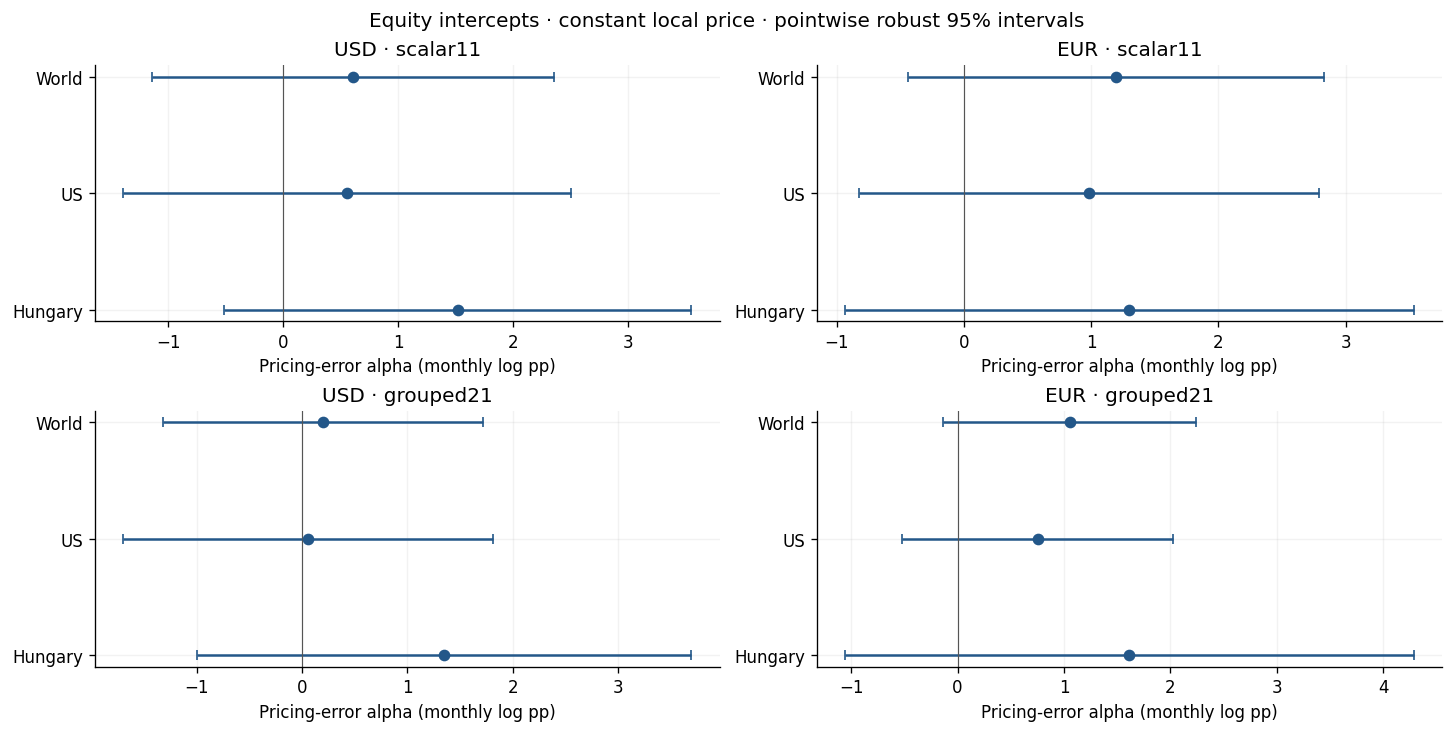

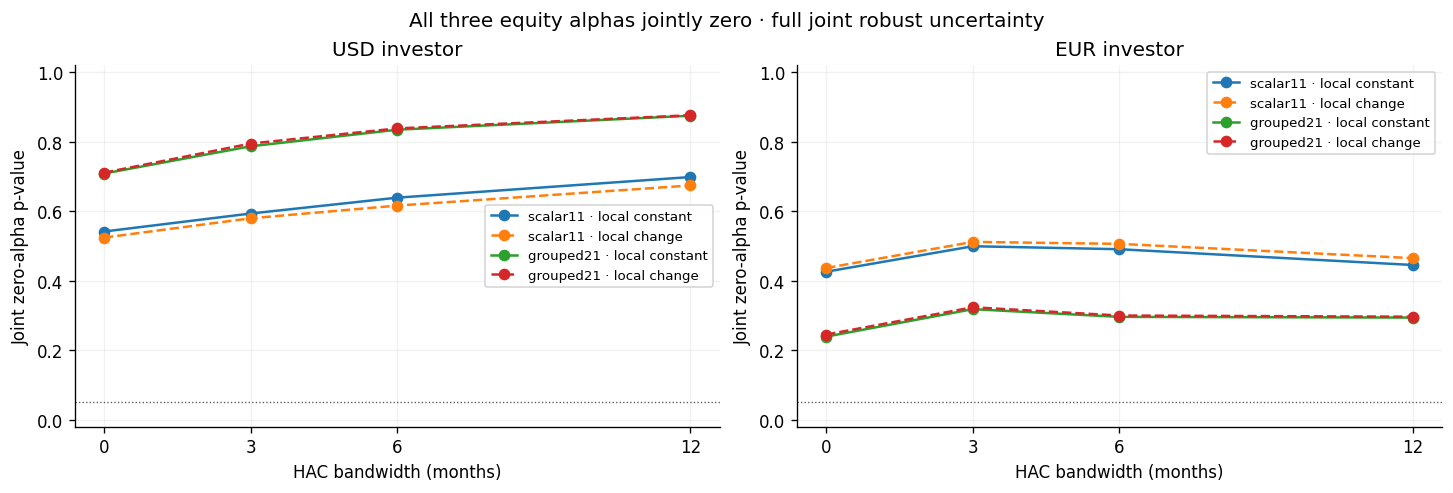

In [5]:
fig,axes=plt.subplots(len(COVARIANCE_MODELS),2,figsize=(12,3*len(COVARIANCE_MODELS)),layout="constrained",squeeze=False)
for col,currency in enumerate(["USD","EUR"]):
    for row,name in enumerate(COVARIANCE_MODELS):
        ax=axes[row,col];rows=alphas.loc[(f"{currency}_{name}_constant_free",0)].reindex(EQUITIES)
        for j,(equity,q) in enumerate(rows.iterrows()):
            if np.isfinite(q["robust_se_pp"]):ax.errorbar(q["alpha_monthly_pp"],j,xerr=1.96*q["robust_se_pp"],fmt="o",capsize=3,color="#235789")
            else:ax.plot(q["alpha_monthly_pp"],j,marker="x",color="#888888")
        ax.axvline(0,color="#555555",lw=.7);ax.set(yticks=range(3),yticklabels=EQUITIES,title=f"{currency} · {name}",xlabel="Pricing-error alpha (monthly log pp)")
        ax.invert_yaxis()
fig.suptitle("Equity intercepts · constant local price · pointwise robust 95% intervals")
plt.savefig(OUT/"01_equity_alphas.png",dpi=160,bbox_inches="tight");plt.show();plt.close()
fig,axes=plt.subplots(1,2,figsize=(12,4),layout="constrained",squeeze=False)
for ax,currency in zip(axes[0],["USD","EUR"]):
    for name in COVARIANCE_MODELS:
        for specification in local_specifications:
            key=f"{currency}_{name}_{specification}_free";rows=tests.xs((key,"Equity alphas jointly zero"),level=("case","test")).reindex(HAC_LAGS)
            label=f"{name} · local {specification}"
            if rows["robust_p_value"].notna().any():ax.plot(HAC_LAGS,rows["robust_p_value"],marker="o",ls="-" if specification=="constant" else "--",label=label)
            else:ax.plot([],[],label=label+": withheld")
    ax.axhline(.05,color="#555555",lw=.8,ls=":");ax.set(title=f"{currency} investor",xlabel="HAC bandwidth (months)",ylabel="Joint zero-alpha p-value",xticks=HAC_LAGS,ylim=(-.02,1.02));ax.legend(fontsize=8)
fig.suptitle("All three equity alphas jointly zero · full joint robust uncertainty")
plt.savefig(OUT/"02_joint_alpha_HAC.png",dpi=160,bbox_inches="tight");plt.show();plt.close()

## 5. Save the audit and final comparison

Export full joint uncertainty, physical-unit alpha estimates, all restrictions, risk-price estimates,
residual screens, designs, fitted price paths and Hungary's conditional-mean decomposition. The
pricing-error intercept is a separate component; it is not counted as a risk premium. The main table
uses constant Hungarian local pricing; the audited time-varying-local design stays a sensitivity.

In [6]:
tables={"fit_summary.csv":summary,"restriction_tests.csv":tests,"alpha_estimates.csv":alphas,"price_coefficients.csv":price_coefficients,
    "mean_loading_audit.csv":mean_loading_audit,"mean_diagnostics.csv":mean_diagnostics,"residual_diagnostics.csv":residuals,
    "cross_covariance_diagnostics.csv":cross_diagnostics,"starting_points.csv":starting_points}
for name,table in tables.items():table.to_csv(OUT/name)
for key,case in fits.items():
    f,inf=case["filter"],case["inference"]
    np.savez_compressed(OUT/f"parameters_{key}.npz",theta=case["theta"],H=f["H"],mu=f["mu"],pricing_mu=f["pricing_mu"],equity_alphas=f["equity_alphas"],residuals=f["errors"],scores=f["scores"],Hessian=inf["Hessian"],**{f"covariance_HAC{h}":v["covariance"] for h,v in inf["estimates"].items()})
    case["premia"].to_csv(OUT/f"Hungary_decomposition_{key}.csv")
    pd.DataFrame({"world":f["world_prices"],"HUF_FX":f["fx_prices"][:,0],"other_FX":f["fx_prices"][:,1],"HU_local":f["local_prices"]},index=data.index).to_csv(OUT/f"price_paths_{key}.csv")
    for label,z in case["pdesign"].items():pd.DataFrame(z,index=data.index,columns=case["columns"][label]).to_csv(OUT/f"design_{key}_{label}.csv")
record={"model_version":MODEL_VERSION,"snapshot":SNAPSHOT,"source_dataset_sha256":manifest["exports"]["dataset.csv"],"first":str(data.index[0]),"last":str(data.index[-1]),"observations":len(data),
    "covariance_models":COVARIANCE_MODELS,"primary_local":"constant","local_specifications":local_specifications,"equity_alphas":EQUITIES,"alpha_units":"monthly log percentage points; optimized in fixed sample SD units",
    "HAC_lags":HAC_LAGS,"test_lags":TEST_LAGS,"SE_step_tolerance":SE_STEP_TOL,"engines":engine_hashes,"upstream":UPSTREAM,"upstream_file_sha256":upstream_hashes,
    "conditioning_root":str(conditioning_root.relative_to(ROOT)),"conditioning_file_sha256":conditioning_hashes,"world_FX_instruments":prior["world_FX_instruments"],"python":platform.python_version(),"packages":versions}
(OUT/"estimation_manifest.json").write_text(json.dumps(record,indent=2,sort_keys=True)+"\n")
final_rows=[]
for key,row in summary[summary["free_alpha"]].iterrows():
    p=tests.xs((key,"Equity alphas jointly zero"),level=("case","test"))["robust_p_value"].reindex(HAC_LAGS)
    final_rows.append({"case":key,"primary":row["local_specification"]=="constant","n":row["n"],"parameters":row["parameters"],"AIC_change":row["AIC_minus_zero_alpha"],"BIC_change":row["BIC_minus_zero_alpha"],"ready":row["ready_all_lags"],
        "joint_alpha_p_HAC0":p.loc[0],"joint_alpha_p_min":p.min(),"joint_alpha_p_max":p.max(),"variance_flags":row["variance_flags"],"cross_flags":row["cross_flags"]})
final_summary=pd.DataFrame(final_rows).set_index("case");final_summary.to_csv(OUT/"final_summary.csv")
display(Markdown("**Primary joint zero-alpha results — constant Hungarian local pricing**"));display(final_summary[final_summary["primary"]].drop(columns="primary"))
display(alphas.xs(0,level="HAC_lags").loc[[key for key in final_summary[final_summary["primary"]].index]])
primary_keys=list(final_summary[final_summary["primary"]].index)
primary_alpha_p=tests.loc[[(key,h,"Equity alphas jointly zero") for key in primary_keys for h in HAC_LAGS],"robust_p_value"]
if primary_alpha_p.notna().all() and (primary_alpha_p>.05).all():
    display(Markdown(f"**Interpretation:** zero equity alphas are not jointly rejected at 5% in any primary specification or fixed bandwidth "
        f"(p-values **{primary_alpha_p.min():.4f}–{primary_alpha_p.max():.4f}**). This does not establish economically small errors; inspect the interval widths."))
if (final_summary.loc[primary_keys,["AIC_change","BIC_change"]]>0).all().all():
    display(Markdown("Both AIC and BIC favor the matched **zero-alpha restrictions** in all primary comparisons."))
primary_fx_p=tests.loc[[(key,h,"FX prices constant") for key in primary_keys for h in HAC_LAGS],"robust_p_value"]
if primary_fx_p.notna().all() and (primary_fx_p<.05).all():
    display(Markdown("Allowing equity alphas leaves **joint FX-price constancy rejected** in every primary model and fixed bandwidth; this remains a conditional specification result."))
if RUN_TV_LOCAL_SENSITIVITY:
    display(Markdown("**Audited time-varying local-price sensitivity**"));display(final_summary[~final_summary["primary"]].drop(columns="primary"))
display(Markdown("Read joint alpha tests alongside identification, residual diagnostics, individual estimates, both covariance models and all fixed bandwidths. "
    "Zero alpha is a conditional pricing restriction, not proof of correct specification or absence of economically meaningful mispricing. "
    "A consistent final model ladder, remaining robustness checks and the research synthesis remain. "
    f"Outputs: `{OUT.relative_to(ROOT)}`. The frozen data and upstream outputs were read without updating them."))

**Primary joint zero-alpha results — constant Hungarian local pricing**

,n,parameters,AIC_change,BIC_change,ready,joint_alpha_p_HAC0,joint_alpha_p_min,joint_alpha_p_max,variance_flags,cross_flags
case,,,,,,,,,,
USD_scalar11_constant_free,321,37,4.24643,15.5608,True,0.541112,0.541112,0.697818,4,0
USD_grouped21_constant_free,321,44,4.74226,16.0566,True,0.707911,0.707911,0.874096,1,0
EUR_scalar11_constant_free,321,37,3.05742,14.3717,True,0.425603,0.425603,0.498848,1,1
EUR_grouped21_constant_free,321,44,1.18693,12.5013,True,0.238911,0.238911,0.317888,0,0


alpha_monthly_pp  robust_se_pp  \
case                        equity                                    
USD_scalar11_constant_free  Hungary           1.51674       1.03732   
                            US                0.55444      0.995007   
                            World            0.605681      0.892266   
USD_grouped21_constant_free Hungary           1.34958       1.19757   
                            US              0.0576538      0.896447   
                            World            0.201573      0.775541   
EUR_scalar11_constant_free  Hungary           1.30037       1.13939   
                            US               0.985339      0.921503   
                            World             1.19346      0.834486   
EUR_grouped21_constant_free Hungary           1.61477       1.36299   
                            US               0.752053      0.648427   
                            World             1.05337      0.607935   

                                     lower95_pp  upper95_pp  individual_p  \
case                        equity                                          
USD_scalar11_constant_free  Hungary   -0.516411     3.54989      0.143695   
                            US         -1.39577     2.50465      0.577376   
                            World      -1.14316     2.35452      0.497257   
USD_grouped21_constant_free Hungary   -0.997657     3.69682      0.259771   
                            US         -1.69938     1.81469       0.94872   
                            World      -1.31849     1.72163      0.794931   
EUR_scalar11_constant_free  Hungary   -0.932825     3.53357      0.253748   
                            US        -0.820806     2.79148      0.284946   
                            World     -0.442131     2.82906      0.152667   
EUR_grouped21_constant_free Hungary    -1.05668     4.28623      0.236123   
                            US        -0.518863     2.02297      0.246125   
                            World     -0.138183     2.24492     0.0831487   

                                     individual_holm_p  inference_ready  \
case                        equity                                        
USD_scalar11_constant_free  Hungary           0.431084             True   
                            US                0.994514             True   
                            World             0.994514             True   
USD_grouped21_constant_free Hungary           0.779312             True   
                            US                       1             True   
                            World                    1             True   
EUR_scalar11_constant_free  Hungary           0.507497             True   
                            US                0.507497             True   
                            World                0.458             True   
EUR_grouped21_constant_free Hungary           0.472247             True   
                            US                0.472247             True   
                            World             0.249446             True   

                                                reason  
case                        equity                      
USD_scalar11_constant_free  Hungary  numerically ready  
                            US       numerically ready  
                            World    numerically ready  
USD_grouped21_constant_free Hungary  numerically ready  
                            US       numerically ready  
                            World    numerically ready  
EUR_scalar11_constant_free  Hungary  numerically ready  
                            US       numerically ready  
                            World    numerically ready  
EUR_grouped21_constant_free Hungary  numerically ready  
                            US       numerically ready  
                            World    numerically ready

**Interpretation:** zero equity alphas are not jointly rejected at 5% in any primary specification or fixed bandwidth (p-values **0.2389–0.8741**). This does not establish economically small errors; inspect the interval widths.

Both AIC and BIC favor the matched **zero-alpha restrictions** in all primary comparisons.

Allowing equity alphas leaves **joint FX-price constancy rejected** in every primary model and fixed bandwidth; this remains a conditional specification result.

**Audited time-varying local-price sensitivity**

,n,parameters,AIC_change,BIC_change,ready,joint_alpha_p_HAC0,joint_alpha_p_min,joint_alpha_p_max,variance_flags,cross_flags
case,,,,,,,,,,
USD_scalar11_change_free,321,39,4.26999,15.5843,True,0.523664,0.523664,0.673615,4,0
USD_grouped21_change_free,321,46,4.76352,16.0778,True,0.710346,0.710346,0.875503,1,0
EUR_scalar11_change_free,321,39,3.08622,14.4005,True,0.43622,0.43622,0.511359,1,1
EUR_grouped21_change_free,321,46,1.22846,12.5428,True,0.244836,0.244836,0.323315,0,0


Read joint alpha tests alongside identification, residual diagnostics, individual estimates, both covariance models and all fixed bandwidths. Zero alpha is a conditional pricing restriction, not proof of correct specification or absence of economically meaningful mispricing. A consistent final model ladder, remaining robustness checks and the research synthesis remain. Outputs: `output/11_pricing_errors/fixed_2026-11-13/2000-01_2026-09/equity_alphas`. The frozen data and upstream outputs were read without updating them.